# food-cap-test: A9 mouthful cap, pre-merge test notebook

Branch `food-cap` (2026-10-15). **Defect A9:** the Phase-3 mouthful
`(m_scale/25)·score·F` was capped only by private headroom, never by the food
present, so `F_food` went negative whenever `m_scale·score > 25`, and a negative
`F` then made later mouthfuls negative (live cells with negative `f_priv`).

**Fix:** `M = min((m_scale/25)·max(0,score)·F, max(F,0), max(1−f,0))`, behind the
metaparameter `food_cap` (default **1** = capped; **0** = legacy rule,
bit-for-bit main `a0798d1`).

Sections: 1. the defect on main, 2. the fix, 3. parity (`food_cap=0` == main;
`food_cap=1` == main at `m_scale ≤ 1`), 4. impact study (capped vs legacy in the
productive regime).

In [1]:
import os, sys, hashlib
ROOT = os.getcwd()
while not os.path.exists(os.path.join(ROOT, 'C', 'evoca.h')):
    ROOT = os.path.dirname(ROOT)
sys.path.insert(0, os.path.join(ROOT, 'python'))
sys.path.insert(0, os.path.join(ROOT, 'tests'))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from evoca_py import EvoCA
from evoca_explore import build_sim
LEGACY, CAPPED = '#eb6834', '#2a78d6'   # categorical slots 2, 1
print('repo root:', ROOT)

repo root: /Users/n/Projects/EvoCA/.claude/worktrees/agent-af66da74856ae5d09


## 1. The defect on main

`food_cap=0` is the legacy rule; section 3 shows it is bit-identical to main, so
this is the main behavior. A9 config: N=96, 1500 steps, `food_inc=0.015`,
`tax=0.01`, seed 1, via `build_sim`.

In [2]:
def trace(m_scale, food_cap, N=96, T=1500, seed=1):
    s = build_sim(dict(food_inc=0.015, m_scale=m_scale, tax=0.01, food_cap=food_cap), N=N, seed=seed)
    minF, minf, negfrac = [], [], []
    for _ in range(T):
        s.step()
        F, a, f = s.get_F(), s.get_alive().astype(bool), s.get_f()
        minF.append(F.min()); negfrac.append((F < 0).mean())
        minf.append(f[a].min() if a.any() else np.nan)
    dens = s.get_alive().mean(); s.free()
    return np.array(minF), np.array(minf), np.array(negfrac), dens

rows, traces = [], {}
for fc in (0, 1):
    for m in (1.0, 2.0, 3.0, 4.0):
        mF, mf, nf, d = trace(m, fc)
        traces[(fc, m)] = mF
        rows.append(dict(food_cap=fc, m_scale=m, min_F=mF.min(), min_alive_f=np.nanmin(mf),
                         max_frac_F_neg=nf.max(), final_density=d))
tab = pd.DataFrame(rows); print(tab.round(3).to_string(index=False))

 food_cap  m_scale  min_F  min_alive_f  max_frac_F_neg  final_density
        0      1.0  0.001        0.434           0.000          1.000
        0      2.0 -0.125        0.358           0.835          1.000
        0      3.0 -0.601       -1.026           0.998          1.000
        0      4.0 -0.656       -1.783           0.601          0.992
        1      1.0  0.001        0.434           0.000          1.000
        1      2.0  0.000        0.009           0.000          1.000
        1      3.0  0.000        0.000           0.000          1.000
        1      4.0  0.000        0.000           0.000          1.000


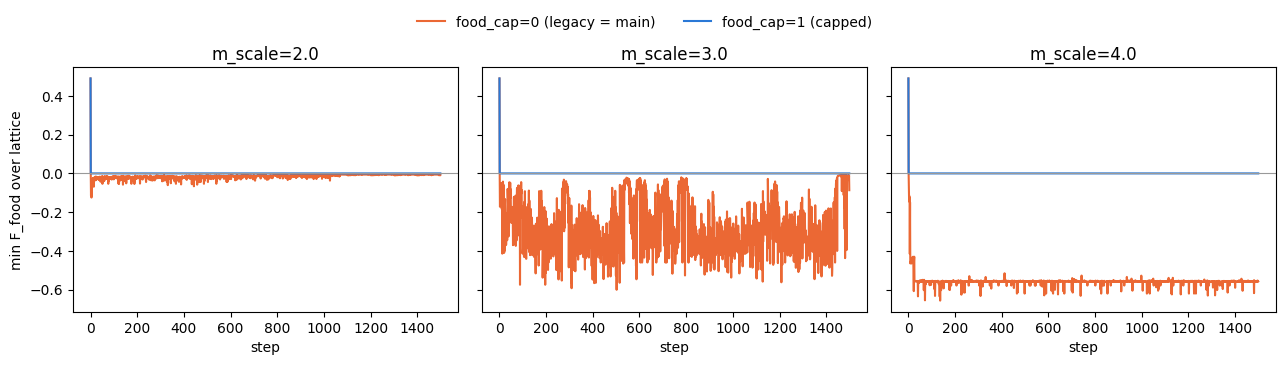

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
for ax, m in zip(axes, (2.0, 3.0, 4.0)):
    ax.plot(traces[(0, m)], color=LEGACY, lw=1.5, label='food_cap=0 (legacy = main)')
    ax.plot(traces[(1, m)], color=CAPPED, lw=1.5, label='food_cap=1 (capped)')
    ax.axhline(0, color='0.6', lw=0.8); ax.set_title(f'm_scale={m}'); ax.set_xlabel('step')
axes[0].set_ylabel('min F_food over lattice')
fig.legend(*axes[0].get_legend_handles_labels(), loc='upper center', ncol=2, bbox_to_anchor=(0.5, 1.08), frameon=False)
plt.tight_layout(); plt.show()

## 2. The fix: `food_cap=1` keeps `F ≥ 0` and alive `f ≥ 0`

In [4]:
cap = tab[tab.food_cap == 1]
ok = (cap.min_F >= 0).all() and (cap.min_alive_f >= 0).all() and (cap.final_density > 0.1).all()
leg = tab[(tab.food_cap == 0) & (tab.m_scale >= 3)]
print('capped: F>=0, alive f>=0, viable at all m_scale:', ok)
print('legacy still overdraws at m_scale>=3:', bool((leg.min_F < 0).all()))
assert ok and (leg.min_F < 0).all()
print('PASS')

capped: F>=0, alive f>=0, viable at all m_scale: True
legacy still overdraws at m_scale>=3: True
PASS


## 3. Parity

(a) `food_cap=0` vs golden fingerprints recorded on main `a0798d1` (same as
`tests/test_food_cap.py`). (b) At `m_scale ≤ 1` the cap never binds
(`score ≤ 25` ⇒ mouthful ≤ F), so capped == legacy bit-for-bit. (c) The
`tools/parity_probe.py` fixture has `m_scale=1.5`, so the **default** path
changes there; `parity_probe.py run <root> <out> 0` is the merge-gate parity
(result recorded below from the branch run).

In [5]:
from test_food_cap import _MAIN_GOLDEN
class _Make:
    def __init__(self): self.sims = []
    def __call__(self, N, **kw):
        s = EvoCA(); s.init(N, **kw); self.sims.append(s); return s
def golden_fp(m, **kw):
    mk = _Make(); N = 32; rng = np.random.default_rng(5)
    s = mk(N, food_inc=0.015, m_scale=m, gdiff=0.08, tax=0.01, mu_lut=0.01, mu_egenome=0.03, **kw)
    s.set_seed(5); s.state(lut='gol', egenome='uniform', egenome_value=0b000011)
    s.set_v(rng.integers(0, 2, (N, N), dtype=np.uint8)); s.set_f_all(0.5); s.set_F_all(1.0); s.set_alive_halfplane(0)
    for _ in range(200): s.step()
    h = hashlib.sha1()
    for a in (s.get_F(), s.get_f(), s.get_v(), s.get_alive(), s.get_lut_hashes()):
        h.update(np.ascontiguousarray(a).tobytes())
    s.free(); return h.hexdigest()
for m in (3.0, 4.0):
    g0 = golden_fp(m, food_cap=0); g1 = golden_fp(m)
    print(f'm_scale={m}: food_cap=0 == main golden: {g0 == _MAIN_GOLDEN[m]};  food_cap=1 == main: {g1 == _MAIN_GOLDEN[m]}')
    assert g0 == _MAIN_GOLDEN[m] and g1 != _MAIN_GOLDEN[m]

def fp_run(m, fc, N=48, T=600):
    s = build_sim(dict(food_inc=0.01, m_scale=m, gdiff=0.08, tax=0.03, mu_lut=0.01, mu_egenome=0.03, food_cap=fc), N=N, seed=2)
    for _ in range(T): s.step()
    out = [s.get_F().tobytes(), s.get_f().tobytes(), s.get_v().tobytes(), s.get_alive().tobytes(), s.get_lut_hashes().tobytes()]
    d = s.get_alive().mean(); s.free(); return out, d
for m in (0.5, 1.0):
    a, d = fp_run(m, 1); b, _ = fp_run(m, 0)
    print(f'm_scale={m}: capped == legacy bit-for-bit: {a == b}  (density {d:.3f})')
    assert a == b
print('PASS')

m_scale=3.0: food_cap=0 == main golden: True;  food_cap=1 == main: False
m_scale=4.0: food_cap=0 == main golden: True;  food_cap=1 == main: False


m_scale=0.5: capped == legacy bit-for-bit: True  (density 0.227)


m_scale=1.0: capped == legacy bit-for-bit: True  (density 0.280)
PASS


In [6]:
print('tools/parity_probe.py (N=128, m_scale=1.5, 2 run_sim seeds + 1200-step trajectory), branch vs main a0798d1:')
PARITY_TEXT = '''food_cap=0 (run <root> <out> 0) vs main:
  run_sim_1 common 83 new keys ['param_food_cap'] lost []
  run_sim_2 common 83 new keys ['param_food_cap'] lost []
  traj IDENTICAL
  BAD 0
food_cap=1 (default) vs main: traj DIFFERENT, BAD 120 (expected: m_scale=1.5 > 1),
  fixture viable in both (extinct 0/0; final density 0.338 main vs 0.334 capped)'''
print(PARITY_TEXT)

tools/parity_probe.py (N=128, m_scale=1.5, 2 run_sim seeds + 1200-step trajectory), branch vs main a0798d1:
food_cap=0 (run <root> <out> 0) vs main:
  run_sim_1 common 83 new keys ['param_food_cap'] lost []
  run_sim_2 common 83 new keys ['param_food_cap'] lost []
  traj IDENTICAL
  BAD 0
food_cap=1 (default) vs main: traj DIFFERENT, BAD 120 (expected: m_scale=1.5 > 1),
  fixture viable in both (extinct 0/0; final density 0.338 main vs 0.334 capped)


## 4. Impact study: capped vs legacy in the productive regime

`Research/Resource-driving/Scans/2026-10-15_food_cap_impact/` (`scan.py`,
`results.csv`): N=128, 8000 ticks, 4 seeds, each config run with `food_cap=0`
and `1` on the same seeds. Groups: an `m_scale × food_inc` sweep on the
pure-evo joint-winner base (winner = `m_scale 2.5, food_inc 0.018`); R1 rows 225
and 174 (`m_scale 3.5`); the #3c/#8 regime (`m_scale 3.0`). `c_*` columns come
from a companion headless run (shadow off, so a different trajectory, same
params and seed). In the sweep figure the grey band marks the R1 "productive interior" `m_scale` 2.5–3.5. Viability and the excess slopes come from run_sim (shadow on).

In [7]:
R = pd.read_csv(os.path.join(ROOT, 'Research/Resource-driving/Scans/2026-10-15_food_cap_impact/results.csv'))
assert (R.error.fillna('') == '').all()
R['viable'] = 1 - R.extinct
cols = ['viable', 'alive_density_mean', 'c_F_mean', 'c_f_alive_mean', 'c_birth_rate', 'c_negF_frac',
        'mean_intake_mean', 'dyn_excess_pc_slope', 'eg_excess_pc_slope']
key = ['group', 'param_food_inc', 'param_m_scale', 'param_food_cap']
T = R.groupby(key)[cols].mean().reset_index()
pd.set_option('display.width', 220)
print(T.round(4).to_string(index=False))

  group  param_food_inc  param_m_scale  param_food_cap  viable  alive_density_mean  c_F_mean  c_f_alive_mean  c_birth_rate  c_negF_frac  mean_intake_mean  dyn_excess_pc_slope  eg_excess_pc_slope
lin_3c8           0.015            3.0               0    1.00              0.3782    0.3628          0.3744        0.0365       0.0647            0.0487               3.7636              2.9695
lin_3c8           0.015            3.0               1    1.00              0.3698    0.4037          0.4082        0.0220       0.0000            0.0447               6.2370              2.6014
 r1_174           0.018            3.5               0    1.00              0.4839    0.2546          0.5207        0.0030       0.0587            0.0398              14.1427             90.0551
 r1_174           0.018            3.5               1    1.00              0.4731    0.2580          0.5278        0.0027       0.0000            0.0374              14.1805             93.4774
 r1_225           0.013  

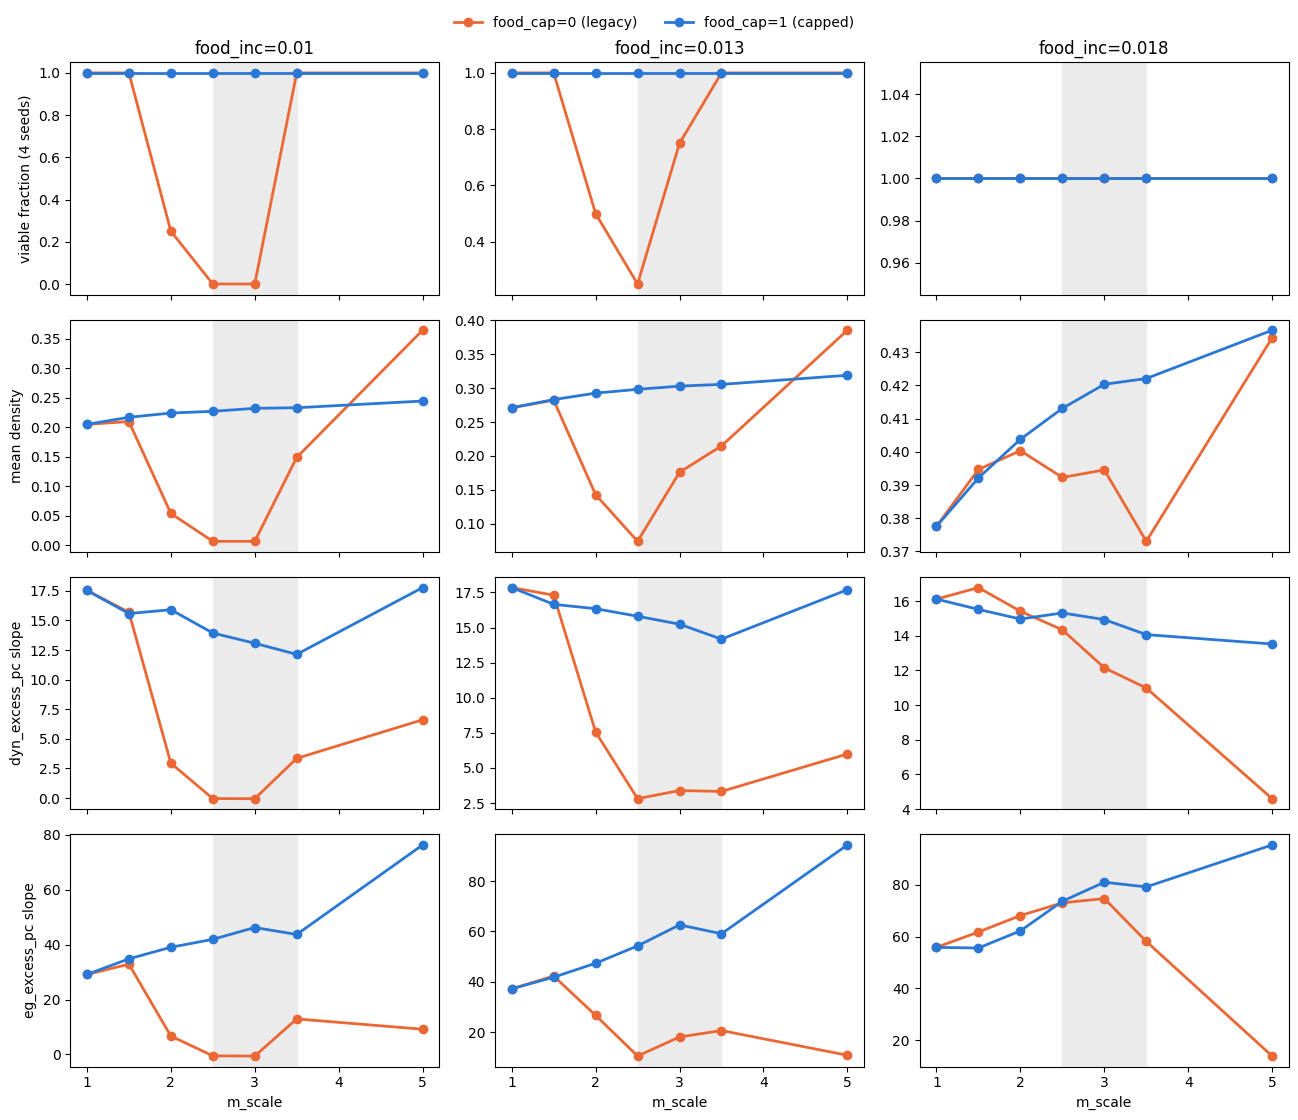

In [8]:
sw = T[T.group == 'sweep']
metrics = [('viable', 'viable fraction (4 seeds)'), ('alive_density_mean', 'mean density'),
           ('dyn_excess_pc_slope', 'dyn_excess_pc slope'), ('eg_excess_pc_slope', 'eg_excess_pc slope')]
fis = sorted(sw.param_food_inc.unique())
fig, axes = plt.subplots(len(metrics), len(fis), figsize=(13, 11), sharex=True)
for j, fi in enumerate(fis):
    for i, (mcol, lab) in enumerate(metrics):
        ax = axes[i, j]
        for fc, col, name in ((0, LEGACY, 'food_cap=0 (legacy)'), (1, CAPPED, 'food_cap=1 (capped)')):
            d = sw[(sw.param_food_inc == fi) & (sw.param_food_cap == fc)].sort_values('param_m_scale')
            ax.plot(d.param_m_scale, d[mcol], '-o', color=col, lw=2, ms=6, label=name)
        ax.axvspan(2.5, 3.5, color='0.92', zorder=0)
        if i == 0: ax.set_title(f'food_inc={fi}')
        if j == 0: ax.set_ylabel(lab)
        if i == len(metrics) - 1: ax.set_xlabel('m_scale')
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc='upper center', ncol=2, bbox_to_anchor=(0.5, 1.02), frameon=False)
plt.tight_layout(); plt.show()

In [9]:
# Paired per-seed deltas (capped - legacy) for the named productive configs
named = R[(R.group != 'sweep') | ((R.param_m_scale == 2.5) & (R.param_food_inc == 0.018))].copy()
named['cfg'] = np.where(named.group == 'sweep', 'joint_winner', named.group)
P = named.pivot_table(index=['cfg', 'seed'], columns='param_food_cap',
                      values=['viable', 'alive_density_mean', 'c_birth_rate', 'c_F_mean', 'dyn_excess_pc_slope', 'eg_excess_pc_slope'])
print(P.groupby('cfg').mean().round(4).T.to_string())

cfg                                 joint_winner  lin_3c8   r1_174   r1_225
                    param_food_cap                                         
alive_density_mean  0                     0.3923   0.3782   0.4839   0.3250
                    1                     0.4131   0.3698   0.4731   0.3480
c_F_mean            0                     0.3352   0.3628   0.2546   0.3131
                    1                     0.3398   0.4037   0.2580   0.3133
c_birth_rate        0                     0.0047   0.0365   0.0030   0.0038
                    1                     0.0044   0.0220   0.0027   0.0031
dyn_excess_pc_slope 0                    14.3439   3.7636  14.1427  19.7640
                    1                    15.3188   6.2370  14.1805  22.2012
eg_excess_pc_slope  0                    72.9705   2.9695  90.0551  39.4005
                    1                    73.5635   2.6014  93.4774  42.5705
viable              0                     1.0000   1.0000   1.0000   1.0000
            

### Verdict on the productive `m_scale` interior (2.5–3.5)

**It does not survive the cap.** With `food_cap=1`, viability is 4/4 at
every `m_scale` in 1–5 and every `food_inc`. Density, food stock and birth
rate change smoothly and weakly with `m_scale`. `dyn_excess_pc_slope` is
flat (about 13–18), and `eg_excess_pc_slope` rises monotonically up to the
grid edge at 5.0. Under the legacy rule, A9 built the interior from both
ends:
* under scarcity, extinctions at intermediate `m_scale` 2–3 (R1's "U-shaped
  viability" is an A9 artifact);
* at `m_scale` 5, debt-fed churn: 17–21% of sites with F<0, birth rate
  25–35× capped, and `eg_excess` collapsing to 9–14 (76–95 capped).

The pure-evo joint winner (2.5, 0.018) is essentially unchanged, as are R1
rows 225 and 174, apart from about 20% fewer births. The #3c/#8 regime keeps
its mean density but has 40% fewer births and higher dyn excess. Under the
cap, eating saturates once `m_scale·score ≥ 25`, so high `m_scale` relaxes
selection on egene specificity (specificity falls with `m_scale`). Whether
the rising `eg_excess` there means productive novelty still needs
interpretation. The re-run list is in
`Research/Resource-driving/Scans/2026-10-15_food_cap_impact/notes.md`.